# Assignment 1: EDA and Baseline
GROUP50_CENG313, LLM Classification Finetuning

In [2]:
# Colab: clone the repo so src/ can be imported
# !git clone https://github.com/akdagdev/GROUP50_CENG313.git
# %cd GROUP50_CENG313
from src.data import load_train, load_test
from src.utils import set_seed
set_seed(42)

## 1. Data overview


Each row compares two model conversations for the same prompts. A conversation may contain one or more turns.

id is the comparison ID.

model_a and model_b are the model names.

prompt contains user messages stored as a JSON list.

response_a and response_b contain each model's replies as JSON lists.

winner_model_a, winner_model_b and winner_tie are the outcome labels (0 or 1).

In [3]:
import pandas as pd

df = pd.read_csv("./data/train.csv")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Each target column is 1 when that outcome was selected.
winner_cols = ["winner_model_a", "winner_model_b", "winner_tie"]
class_counts = df[winner_cols].sum()
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2)
})
print("\nClass distribution:")
print(class_distribution.to_string())


Rows: 57477
Columns: 9

Class distribution:
                Count  Percentage
winner_model_a  20064       34.91
winner_model_b  19652       34.19
winner_tie      17761       30.90


## 2. Data quality (missing values, duplicates, inconsistencies)

In [4]:
# We are checking if there are any missing values in the dataset.
df.isna().sum()

id                0
model_a           0
model_b           0
prompt            0
response_a        0
response_b        0
winner_model_a    0
winner_model_b    0
winner_tie        0
dtype: int64

No column level missing values were found.

In [5]:
# Now we are checking if there is null values in the dataset.
import json

for sutun in ["prompt", "response_a", "response_b"]:
    sayi = sum([1 for i in df[sutun] if None in json.loads(i) or "" in json.loads(i) or " " in json.loads(i)])
    print(sutun, sayi)

prompt 5
response_a 133
response_b 143


At least one empty entry was found in 5 rows of prompt, 133 rows of response_a, and 143 rows of response_b.

In [6]:
# Check for duplicate records at three levels.
print("Fully duplicated rows:", df.duplicated().sum())

print(
    "Repeated prompt-response combinations:",
    df.duplicated(subset=["prompt", "response_a", "response_b"]).sum()
)

print(
    "Repeated prompt-response combinations with the same models:",
    df.duplicated(subset=["prompt", "model_a", "model_b", "response_a", "response_b"]).sum()
)


Fully duplicated rows: 0
Repeated prompt-response combinations: 71
Repeated prompt-response combinations with the same models: 8


No fully duplicated rows were found. However, 71 additional rows contain identical prompt-response combinations. When model names are also included in the comparison, 8 additional rows are duplicated on these selected columns. It means these 8 rows differ in IDs or winner labels.

In [7]:
# Check JSON list structure, turn types, and matching conversation lengths.
import json

gecersiz_yapi = 0
gecersiz_tur = 0
tur_uyusmazligi = 0

for _, satir in df.iterrows():
    konusma = []

    for sutun in ["prompt", "response_a", "response_b"]:
        try:
            turlar = json.loads(satir[sutun])
        except (json.JSONDecodeError, TypeError):
            turlar = None
        konusma.append(turlar)

    if not all(isinstance(turlar, list) and len(turlar) > 0 for turlar in konusma):
        gecersiz_yapi += 1
        continue

    if any(tur is not None and not isinstance(tur, str)
           for turlar in konusma for tur in turlar):
        gecersiz_tur += 1

    sorular, a_cevaplari, b_cevaplari = konusma
    if not (len(sorular) == len(a_cevaplari) == len(b_cevaplari)):
        tur_uyusmazligi += 1

print("Rows with invalid JSON, non-list values, or empty lists:", gecersiz_yapi)
print("Rows with unexpected turn types:", gecersiz_tur)
print("Rows with mismatched conversation lengths:", tur_uyusmazligi)


Rows with invalid JSON, non-list values, or empty lists: 0
Rows with unexpected turn types: 0
Rows with mismatched conversation lengths: 0


All conversation lists are valid, and prompt and response turn counts match in every row.

In [8]:
# Each row must have exactly one winning class marked as 1.
hedef_sutunlari = ["winner_model_a", "winner_model_b", "winner_tie"]
etiketler = df[hedef_sutunlari]

ikili_degerler = etiketler.isin([0, 1]).all(axis=1)
tek_kazanan = etiketler.sum(axis=1) == 1
gecerli_etiketler = ikili_degerler & tek_kazanan

print("Rows with values other than 0 or 1:", (~ikili_degerler).sum())
print("Rows whose winner labels do not sum to 1:", (~tek_kazanan).sum())
print("Rows with invalid winner labels:", (~gecerli_etiketler).sum())


Rows with values other than 0 or 1: 0
Rows whose winner labels do not sum to 1: 0
Rows with invalid winner labels: 0


All winner labels are 0 or 1, with exactly one winning class per row.

In [9]:
# Count rows with at least one null or whitespace-only turn.
for sutun in ["prompt", "response_a", "response_b"]:
    sayi = 0
    for veri in df[sutun]:
        for tur in json.loads(veri):
            if tur is None or (isinstance(tur, str) and tur.strip() == ""):
                sayi += 1
                break
    print(sutun, sayi)


prompt 5
response_a 133
response_b 143


The full whitespace check found 5 affected prompt rows, 133 response_a rows, and 143 response_b rows.

No rows were removed or missing responses filled. The word-count baseline skips null turns. Repeated conversations may overlap between training and validation, so the validation score should be interpreted with this limitation.

## 3. Exploratory analysis and visualizations

In [10]:
import json
import numpy as np
import pandas as pd

def kelime_sayisi(cevap):
    turlar = json.loads(cevap)
    return sum(len(tur.split()) for tur in turlar if isinstance(tur, str))

a_uzunluk = df["response_a"].map(kelime_sayisi)
b_uzunluk = df["response_b"].map(kelime_sayisi)

grup = np.select(
    [a_uzunluk > b_uzunluk, b_uzunluk > a_uzunluk],
    ["A daha uzun", "B daha uzun"],
    default="Eşit uzunluk",
)

sonuc = df[["winner_model_a", "winner_model_b", "winner_tie"]].idxmax(axis=1)
sonuc = sonuc.map({
    "winner_model_a": "A kazandı",
    "winner_model_b": "B kazandı",
    "winner_tie": "Beraberlik",
})

oranlar = pd.crosstab(grup, sonuc, normalize="index") * 100
display(oranlar.round(1))

col_0,A kazandı,B kazandı,Beraberlik
row_0,,,
A daha uzun,43.1,26.6,30.4
B daha uzun,27.2,42.4,30.4
Eşit uzunluk,21.2,21.0,57.8


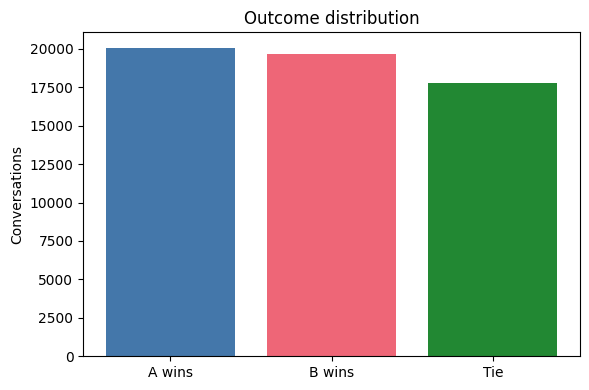

In [11]:
import matplotlib.pyplot as plt

# Number of conversations for each outcome.
class_counts = df[["winner_model_a", "winner_model_b", "winner_tie"]].sum()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["A wins", "B wins", "Tie"], class_counts, color=["#4477AA", "#EE6677", "#228833"])
ax.set_title("Outcome distribution")
ax.set_ylabel("Conversations")
fig.tight_layout()
plt.show()


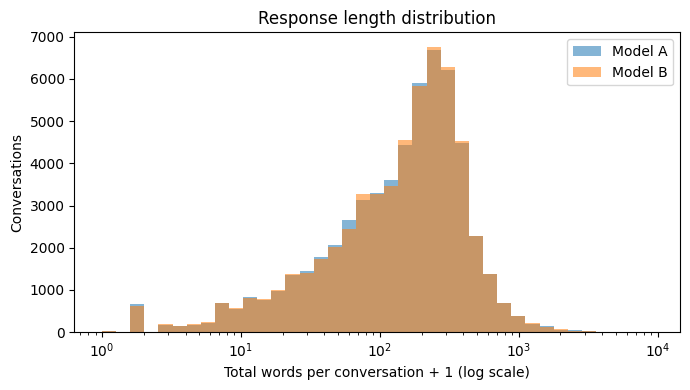

In [12]:
# Logarithmic bins show the long tail without dropping long responses.
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.geomspace(1, max(a_uzunluk.max(), b_uzunluk.max()) + 2, 40)
ax.hist(a_uzunluk + 1, bins=bins, alpha=0.55, label="Model A")
ax.hist(b_uzunluk + 1, bins=bins, alpha=0.55, label="Model B")
ax.set_xscale("log")
ax.set_title("Response length distribution")
ax.set_xlabel("Total words per conversation + 1 (log scale)")
ax.set_ylabel("Conversations")
ax.legend()
fig.tight_layout()
plt.show()


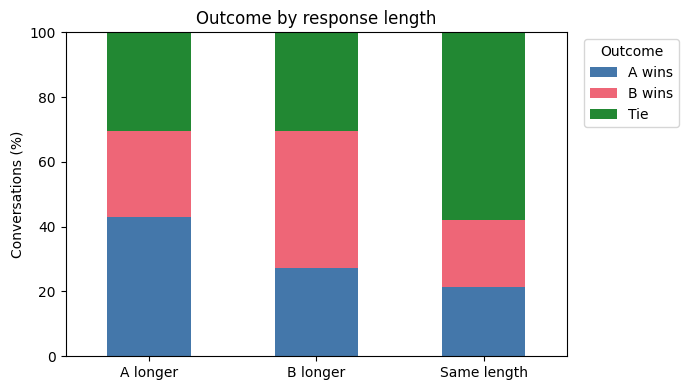

In [13]:
# The percentages in each length group add up to 100.
plot_rates = oranlar.reindex(
    index=["A daha uzun", "B daha uzun", "Eşit uzunluk"],
    columns=["A kazandı", "B kazandı", "Beraberlik"]
).copy()
plot_rates.index = ["A longer", "B longer", "Same length"]
plot_rates.columns = ["A wins", "B wins", "Tie"]
ax = plot_rates.plot.bar(
    stacked=True, figsize=(7, 4), color=["#4477AA", "#EE6677", "#228833"], rot=0
)
ax.set_title("Outcome by response length")
ax.set_xlabel("")
ax.set_ylabel("Conversations (%)")
ax.set_ylim(0, 100)
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
fig = ax.figure
fig.tight_layout()
plt.show()


## 4. Baseline models


In [14]:
import numpy as np
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

winner_cols = ["winner_model_a", "winner_model_b", "winner_tie"]
y = df[winner_cols].to_numpy().argmax(axis=1)

train_idx, val_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=42, stratify=y
)

class_probs = np.bincount(y[train_idx], minlength=3) / len(train_idx)
val_probs = np.tile(class_probs, (len(val_idx), 1))

score = log_loss(y[val_idx], val_probs, labels=[0, 1, 2])
print(f"Validation log loss = {score:.4f}")

Validation log loss = 1.0972


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from scipy.sparse import csr_matrix

X_uzunluk = pd.DataFrame({
    "a_kelime": a_uzunluk,
    "b_kelime": b_uzunluk,
    "kelime_farki": a_uzunluk - b_uzunluk,
})

# Sparse matrix operations avoid the macOS Accelerate matmul warning.
model = make_pipeline(
    StandardScaler(),
    FunctionTransformer(csr_matrix),
    LogisticRegression()
)
model.fit(X_uzunluk.iloc[train_idx], y[train_idx])

tahmin = model.predict_proba(X_uzunluk.iloc[val_idx])
uzunluk_skoru = log_loss(y[val_idx], tahmin, labels=[0, 1, 2])

print(f"Sınıf oranları baseline: {score:.4f}")
print(f"Uzunluk + lojistik regresyon: {uzunluk_skoru:.4f}")

Sınıf oranları baseline: 1.0972
Uzunluk + lojistik regresyon: 1.0709


## 5. Results and conclusions

The dataset contains 57,477 comparisons with three relatively balanced outcomes: model A wins (34.91%), model B wins (34.19%), and ties (30.90%). Although there are no column-level missing values or fully duplicated rows, some conversation lists contain null or blank turns, and 71 additional rows repeat the same prompt-response combination. All conversation lists have valid structures and matching turn counts, and all rows have valid winner labels.

The exploratory analysis shows an association between response length and user preference. When A is longer, A wins in 43.1% of comparisons, while B wins in 26.6%. When B is longer, B wins in 42.4% of comparisons, while A wins in 27.2%. Equal-length responses result in a tie in 57.8% of cases. These findings motivated using response word counts and their difference as baseline features. However, this association does not show that making a response longer causes it to be preferred.

Both baselines were evaluated on the same stratified 80/20 train-validation split with a random seed of 42. Lower log loss indicates better probability predictions.

| Baseline | Validation log loss |
| --- | ---: |
| Training class proportions | 1.0972 |
| Response length + logistic regression | 1.0709 |

Logistic regression reduced validation log loss by 0.0263, approximately 2.4% relative to the class-proportion baseline. This modest improvement suggests that response length provides useful predictive information, but the model does not directly capture response content, correctness, or relevance to the prompt.

These results provide an initial reference for future models. They are based on a single validation split, and repeated conversations may appear in both training and validation, potentially making the scores optimistic. In the next stage, we plan to evaluate TF-IDF text features with logistic regression and use a validation split that keeps repeated conversations together. This will help assess whether text features improve predictions beyond response length under a more reliable evaluation setup.